<a href="https://colab.research.google.com/github/datadigger01/Datahandling/blob/main/Code_example/week_09_missingvalue_replacement_cont.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('https://github.com/datadigger01/Datahandling/raw/main/Data/default_credit_card_missing.csv',encoding="utf-8-sig")
print(df.info())
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Cust_ID     30000 non-null  int64  
 1   LIMIT_BAL   30000 non-null  int64  
 2   SEX         30000 non-null  int64  
 3   EDUCATION   27600 non-null  float64
 4   MARRIAGE    27000 non-null  float64
 5   AGE         29700 non-null  float64
 6   PAY_0       30000 non-null  int64  
 7   PAY_2       30000 non-null  int64  
 8   PAY_3       30000 non-null  int64  
 9   PAY_4       30000 non-null  int64  
 10  PAY_5       30000 non-null  int64  
 11  PAY_6       30000 non-null  int64  
 12  BILL_AMT1   30000 non-null  int64  
 13  BILL_AMT2   30000 non-null  int64  
 14  BILL_AMT3   30000 non-null  int64  
 15  BILL_AMT4   30000 non-null  int64  
 16  BILL_AMT5   30000 non-null  int64  
 17  BILL_AMT6   30000 non-null  int64  
 18  PAY_AMT1    30000 non-null  int64  
 19  PAY_AMT2    30000 non-nul

,Cust_ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_YN
0,1,20000,2,2.0,1.0,24.0,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2.0,2.0,26.0,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2.0,2.0,34.0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2.0,1.0,37.0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2.0,1.0,57.0,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000,1,3.0,1.0,39.0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,29997,150000,1,3.0,NaN,43.0,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,29998,30000,1,2.0,2.0,37.0,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,29999,80000,1,3.0,1.0,41.0,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


### kNN을 이용한 AGE 결측값 대체 (Model-based Imputation, 연속형 변수)

#### - 핵심 아이디어
  - AGE가 관측된 행(학습용)으로 kNN **회귀**모형(kNNRegressor)을 만들고,
  - AGE가 결측인 행의 값을 '가장 가까운 k명의 이웃'의 **(가중)평균**으로 예측해 채운다.
  - AGE는 연속형이므로 다수결이 아니라 평균을 사용하며, 단순 평균·중앙값 대체 결과와 비교한다.

#### - 범주형(EDUCATION)과 달라지는 점
| 구분 | EDUCATION (범주형) | AGE (연속형) |
|---|---|---|
| 모형 | KNeighborsClassifier | KNeighborsRegressor |
| 이웃 결합 방식 | 다수결(최빈값) | 가중평균 |
| 교차검증 분할 | StratifiedKFold | KFold |
| 평가 지표 | 정확도, 혼동행렬 | RMSE, MAE |
| 비교 기준 | 최빈값 대체 | 평균·중앙값 대체 |


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ─────────────────────────────────────────────
# [1단계] AGE 결측 현황 및 분포 확인
# ─────────────────────────────────────────────
target_age = "AGE"
print("[1단계] AGE 결측 개수:", df[target_age].isna().sum())
print(df[target_age].describe().round(2), "\n")


[1단계] AGE 결측 개수: 300
count    29700.00
mean        35.49
std          9.21
min         21.00
25%         28.00
50%         34.00
75%         41.00
max         79.00
Name: AGE, dtype: float64 



In [4]:
# ─────────────────────────────────────────────
# [2단계] 예측에 사용할 변수(특성) 선택
#   - 결측이 없는 19개 변수 사용
#   - 제외: Cust_ID, default_YN(정보 누설 방지), SEX/EDUCATION/MARRIAGE(결측 존재)
# ─────────────────────────────────────────────
features_age = (["LIMIT_BAL"]
                + ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
                + [f"BILL_AMT{i}" for i in range(1, 7)]
                + [f"PAY_AMT{i}" for i in range(1, 7)])
print(f"[2단계] 사용 변수 {len(features_age)}개\n")

[2단계] 사용 변수 19개



In [5]:
# ─────────────────────────────────────────────
# [3단계] 관측 행 / 결측 행 분리
# ─────────────────────────────────────────────
is_na_age = df[target_age].isna()
Xa_obs = df.loc[~is_na_age, features_age]
ya_obs = df.loc[~is_na_age, target_age].astype(float)
Xa_mis = df.loc[is_na_age, features_age]
print(f"[3단계] 관측 행 {len(Xa_obs):,}개 / 결측 행 {len(Xa_mis):,}개\n")

[3단계] 관측 행 29,700개 / 결측 행 300개



In [6]:
# ─────────────────────────────────────────────
# [4단계] 표준화 + kNN 회귀 파이프라인 구성
#   - 분류기 대신 KNeighborsRegressor 사용
#   - weights="distance": 가까운 이웃일수록 평균에 더 큰 가중치를 준다
# ─────────────────────────────────────────────
def make_reg_model(k):
    return make_pipeline(StandardScaler(),
                         KNeighborsRegressor(n_neighbors=k, weights="distance"))

[5단계] k별 5-fold 교차검증 RMSE
  k= 1: 12.7500
  k= 3: 10.5182
  k= 5: 9.9859
  k= 7: 9.7582
  k=11: 9.5135
  k=15: 9.3956
  k=21: 9.3078
  k=30: 9.2444
  k=40: 9.2054
  k=50: 9.1832
  k=60: 9.1666
  k=70: 9.1584
  k=80: 9.1525
  → 선택된 k = 80



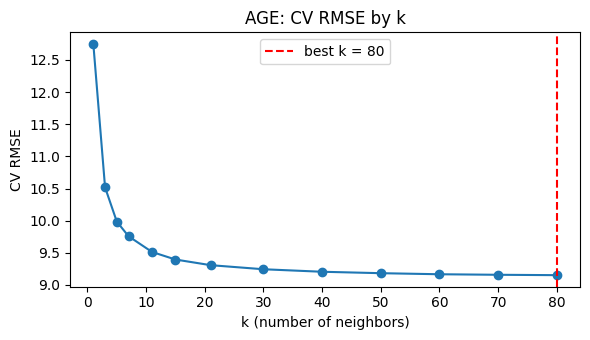

In [10]:
# ─────────────────────────────────────────────
# [5단계] 교차검증으로 최적의 k 선택 (관측 행만 사용)
#   - 연속형 목표변수이므로 층화 없이 KFold 사용
#   - sklearn은 '클수록 좋은' 점수를 쓰므로 RMSE에 음수를 붙여 반환한다
#     → 부호를 다시 바꾸어 RMSE로 해석하고, RMSE가 가장 작은 k를 선택
# ─────────────────────────────────────────────
cv_reg = KFold(n_splits=5, shuffle=True, random_state=1245)
k_list_age = [1, 3, 5, 7, 11, 15, 21, 30, 40, 50, 60, 70, 80]
cv_rmse = {}
print("[5단계] k별 5-fold 교차검증 RMSE")
for k in k_list_age:
    rmse = -cross_val_score(make_reg_model(k), Xa_obs, ya_obs, cv=cv_reg,
                            scoring="neg_root_mean_squared_error").mean()
    cv_rmse[k] = rmse
    print(f"  k={k:>2}: {rmse:.4f}")
best_k_age = min(cv_rmse, key=cv_rmse.get)
print(f"  → 선택된 k = {best_k_age}\n")

# k에 따른 RMSE 변화 시각화
plt.figure(figsize=(6, 3.5))
plt.plot(list(cv_rmse.keys()), list(cv_rmse.values()), marker="o")
plt.axvline(best_k_age, color="red", linestyle="--", label=f"best k = {best_k_age}")
plt.xlabel("k (number of neighbors)")
plt.ylabel("CV RMSE")
plt.title("AGE: CV RMSE by k")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:


# ─────────────────────────────────────────────
# [6단계] 최적 k로 학습 후 결측 행 예측 → 대체
#   - 예측값은 평균이므로 소수가 나온다 → 나이는 정수이므로 반올림
#   - EDUCATION을 대체한 df_imp에 이어서 AGE를 채운다
# ─────────────────────────────────────────────
reg_model = make_reg_model(best_k_age).fit(Xa_obs, ya_obs)
age_pred = reg_model.predict(Xa_mis)

df_imp = df.copy()
df_imp.loc[is_na_age, target_age] = np.round(age_pred)
df_imp[target_age] = df_imp[target_age].astype("Int64")
print("[6단계] 대체 후 AGE 결측 개수:", df_imp[target_age].isna().sum(), "\n")

[6단계] 대체 후 AGE 결측 개수: 0 



[7단계] 결측 위치에서의 대체 오차 (작을수록 좋음)
         RMSE    MAE
평균 대체   9.710  7.961
중앙값 대체  9.819  7.823
kNN 대체  9.382  7.677 

  AGE 기술통계 비교
             원본     평균대체후    kNN대체후
count  30000.00  30000.00  30000.00
mean      35.49     35.49     35.49
std        9.22      9.17      9.17
min       21.00     21.00     21.00
25%       28.00     28.00     28.00
50%       34.00     34.00     34.00
75%       41.00     41.00     41.00
max       79.00     79.00     79.00 



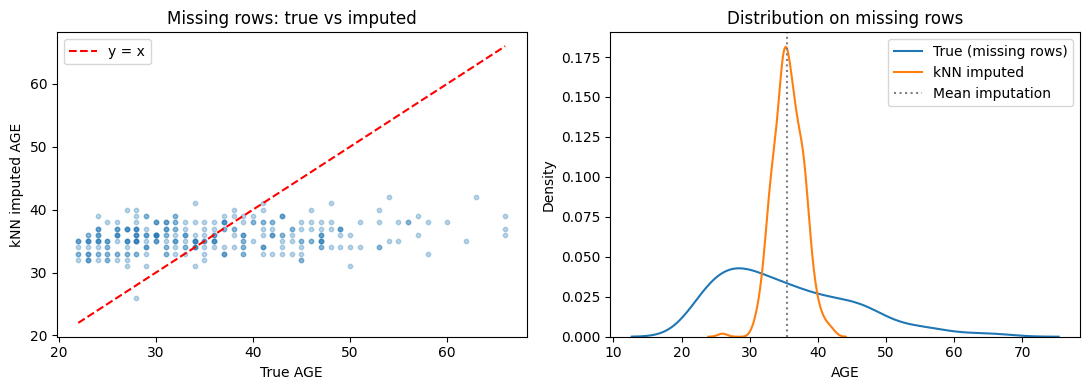

In [12]:
# ─────────────────────────────────────────────
# [7단계] 대체 결과 평가 (실습용: 원본에 정답이 남아 있음)
#   비교 기준: 평균 대체, 중앙값 대체
# ─────────────────────────────────────────────
orig = pd.read_csv('https://github.com/datadigger01/datamining/raw/main/DATA/default_credit_card.csv', encoding="utf-8-sig")
ya_true = orig.loc[is_na_age, target_age].astype(float)
ya_knn  = df_imp.loc[is_na_age, target_age].astype(float)
ya_mean = np.full(len(ya_true), ya_obs.mean())
ya_med  = np.full(len(ya_true), ya_obs.median())

def rmse_fn(y, p):
    return np.sqrt(mean_squared_error(y, p))

eval_age = pd.DataFrame({
    "RMSE": [rmse_fn(ya_true, ya_mean), rmse_fn(ya_true, ya_med), rmse_fn(ya_true, ya_knn)],
    "MAE":  [mean_absolute_error(ya_true, ya_mean),
             mean_absolute_error(ya_true, ya_med),
             mean_absolute_error(ya_true, ya_knn)],
}, index=["평균 대체", "중앙값 대체", "kNN 대체"]).round(3)
print("[7단계] 결측 위치에서의 대체 오차 (작을수록 좋음)")
print(eval_age, "\n")

# 분포 비교: 대체가 원래 분포(퍼짐 정도)를 얼마나 유지하는지
#   - 평균 대체는 한 값에 몰리므로 표준편차가 줄어든다(분산 과소추정)
df_mean_imp = df[target_age].fillna(ya_obs.mean())
dist_age = pd.DataFrame({
    "원본": orig[target_age].describe(),
    "평균대체후": df_mean_imp.describe(),
    "kNN대체후": df_imp[target_age].astype(float).describe(),
}).round(2)
print("  AGE 기술통계 비교")
print(dist_age, "\n")

# 실제값 vs kNN 대체값 시각화
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(ya_true, ya_knn, alpha=0.3, s=10)
lims = [ya_true.min(), ya_true.max()]
axes[0].plot(lims, lims, color="red", linestyle="--", label="y = x")
axes[0].set_xlabel("True AGE")
axes[0].set_ylabel("kNN imputed AGE")
axes[0].set_title("Missing rows: true vs imputed")
axes[0].legend()

sns.kdeplot(ya_true, ax=axes[1], label="True (missing rows)")
sns.kdeplot(ya_knn, ax=axes[1], label="kNN imputed")
axes[1].axvline(ya_obs.mean(), color="gray", linestyle=":", label="Mean imputation")
axes[1].set_xlabel("AGE")
axes[1].set_title("Distribution on missing rows")
axes[1].legend()
plt.tight_layout()
plt.show()